In [1]:
import pandas as pd, numpy as np, glob
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.sparse import hstack
from joblib import Parallel, delayed
import os

In [2]:
path = '/kaggle/input/datasets/swarajmohite/dsai-induction'
# print(os.listdir(path))   

train = pd.read_csv(f'{path}/competition_train.csv')
test  = pd.read_csv(f'{path}/competition_test.csv')
labels = ['toxic','severe_toxic','obscene','threat','insult','identity_hate']

train['comment_text'] = train['comment_text'].fillna('')
test['comment_text']  = test['comment_text'].fillna('')
print(train.shape, test.shape)
train.head()

(127657, 8) (31914, 2)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai000000,"""The citation for the point """"It helped setup ...",0,0,0,0,0,0
1,dsai000001,What i'm talking about are edits such as this ...,0,0,0,0,0,0
2,dsai000002,March 2008 \n Please stop. If you continue to ...,0,0,0,0,0,0
3,dsai000003,"""\nE. J. Thribb2\n\nSo. Farewell then\nMalleus...",1,0,1,0,1,0
4,dsai000004,"Sorry dude, but that's just the way the Wikipe...",0,0,0,0,0,0


1. EDA

toxic            0.0964
severe_toxic     0.0100
obscene          0.0532
threat           0.0030
insult           0.0493
identity_hate    0.0090
dtype: float64


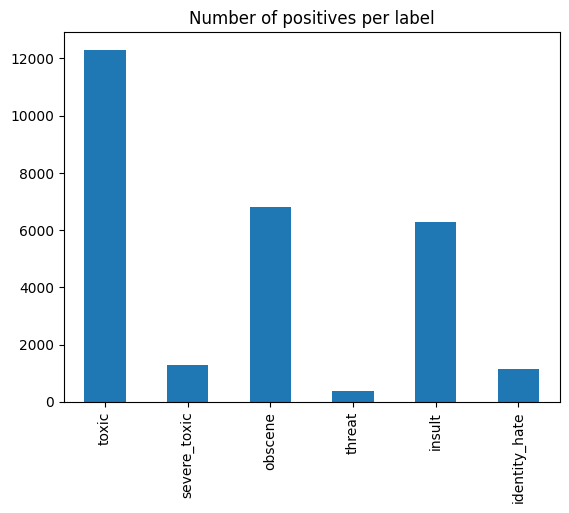

0    114604
1      5131
2      2815
3      3349
4      1423
5       310
6        25
Name: count, dtype: int64


In [3]:
print(train[labels].mean().round(4))     

train[labels].sum().plot(kind='bar', title='Number of positives per label')
plt.show()

print(train[labels].sum(axis=1).value_counts().sort_index())   

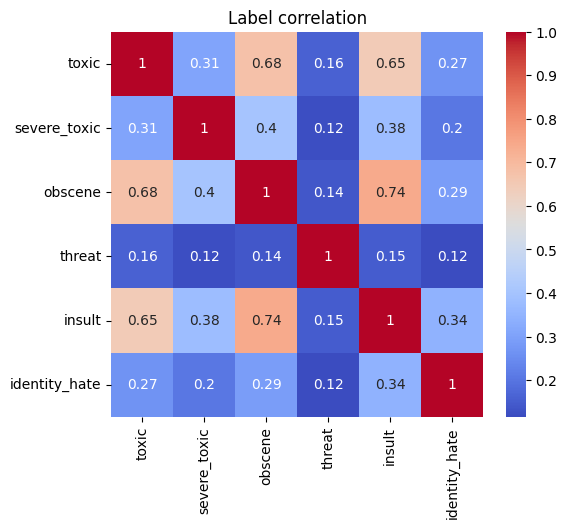

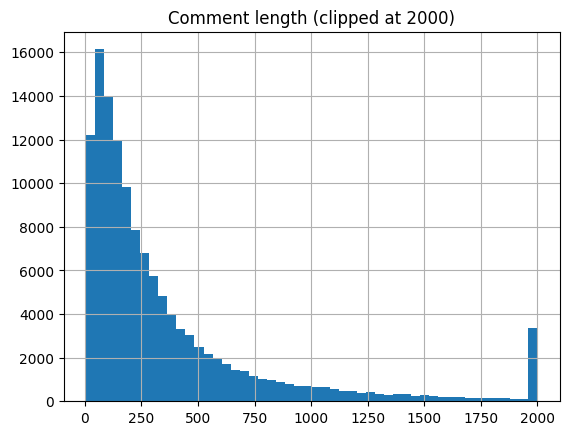

toxic
0    404.120621
1    293.364922
Name: len, dtype: float64
['"\nE. J. Thribb2\n\nSo. Farewell then\nMalleus Fatuorum.\nAdmin fighter. R.I.P.\n""F*** off you stupid c***"" that\nwas your catchphrase\nalong with\n""How old are you, you moronic elitist admin scum, \n17½ ?! .. I think we should be told.""\nso, Rant In Peace, or not\nif that\'s more radical\nand bloody annoying.\n109.153.212.197  "', '"\n\n  BREAKING NEWS!!!! I KNOW THIS IS ONLY FOR THE FRONT PAGE, BUT THIS DESERVES IT!!!!!!!!!!  \n\n Okay. First let me start off by saying that people DO post breaking news, etc. on here. Like t on sept 11th 2001, etc. \n   \n  Anyway there is this new website called ""i-doser.com"" where you can virtually take drugs, such as marijuana, heroin, pills to make it so you can have lucid dreams, etc.""  \n   \nPeople this is extremely serious. I mean we have to make like an article about this or SOMEHTING. Hello you idiots. I mean what if little 8 year olds kids do this eh?  WE are going to 

In [4]:
plt.figure(figsize=(6,5))
sns.heatmap(train[labels].corr(), annot=True, cmap='coolwarm')
plt.title('Label correlation'); plt.show()

train['len'] = train.comment_text.str.len()
train['len'].clip(upper=2000).hist(bins=50)
plt.title('Comment length (clipped at 2000)'); plt.show()
print(train.groupby('toxic')['len'].mean())

print(train[train.toxic==1].comment_text.head(3).tolist())

2. Validation split and scoring

In [5]:
tr, va = train_test_split(train, test_size=0.2, random_state=42, stratify=train['toxic'])

def score(pred_df):
    s = {l: round(roc_auc_score(va[l], pred_df[l]), 4) for l in labels}
    return round(np.mean(list(s.values())), 5), s

# Trains one model per label in parallel (faster)
def run(Xt, yt, Xv, **kw):
    def one(l):
        return LogisticRegression(**kw).fit(Xt, yt[l]).predict_proba(Xv)[:, 1]
    out = Parallel(n_jobs=-1)(delayed(one)(l) for l in labels)
    return pd.DataFrame(dict(zip(labels, out)))

In [6]:
vec = TfidfVectorizer(max_features=20000, stop_words='english')
Xtr = vec.fit_transform(tr.comment_text)
Xva = vec.transform(va.comment_text)

base = run(Xtr, tr, Xva, max_iter=1000)
base_score = score(base)
print('BASELINE mean AUC:', base_score)

BASELINE mean AUC: (np.float64(0.97647), {'toxic': np.float64(0.9689), 'severe_toxic': np.float64(0.9814), 'obscene': np.float64(0.9836), 'threat': np.float64(0.9759), 'insult': np.float64(0.9772), 'identity_hate': np.float64(0.9718)})


In [7]:
all_text = pd.concat([tr.comment_text, test.comment_text])

word_vec = TfidfVectorizer(max_features=50000, ngram_range=(1,2),
                           sublinear_tf=True, strip_accents='unicode')
char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5),
                           max_features=80000, sublinear_tf=True)
word_vec.fit(all_text)
char_vec.fit(all_text)

def feats(s):
    return hstack([word_vec.transform(s), char_vec.transform(s)]).tocsr()

Xtr2 = feats(tr.comment_text)
Xva2 = feats(va.comment_text)
print(Xtr2.shape)

(102125, 130000)


In [8]:
imp = run(Xtr2, tr, Xva2, C=4, solver='liblinear')
imp_score = score(imp)
print('+ char n-grams mean AUC:', imp_score)

+ char n-grams mean AUC: (np.float64(0.98513), {'toxic': np.float64(0.9787), 'severe_toxic': np.float64(0.9871), 'obscene': np.float64(0.9895), 'threat': np.float64(0.9901), 'insult': np.float64(0.9816), 'identity_hate': np.float64(0.9838)})


In [9]:
imp_w = run(Xtr2, tr, Xva2, C=4, solver='liblinear', class_weight='balanced')
impw_score = score(imp_w)
print('+ class_weight mean AUC:', impw_score)

+ class_weight mean AUC: (np.float64(0.98472), {'toxic': np.float64(0.9786), 'severe_toxic': np.float64(0.9873), 'obscene': np.float64(0.9898), 'threat': np.float64(0.9887), 'insult': np.float64(0.982), 'identity_hate': np.float64(0.9819)})


In [10]:
ens = (imp + imp_w) / 2
ens_score = score(ens)

results = pd.DataFrame({
    'Model': ['Baseline (word TF-IDF)', '+ char n-grams', '+ class weights', 'Average of both'],
    'Mean AUC': [base_score[0], imp_score[0], impw_score[0], ens_score[0]]
})
results

,Model,Mean AUC
0,Baseline (word TF-IDF),0.97647
1,+ char n-grams,0.98513
2,+ class weights,0.98472
3,Average of both,0.98492


In [11]:
Xall = feats(train.comment_text)
Xte  = feats(test.comment_text)

# word + char n-grams, no class weights
final = run(Xall, train, Xte, C=4, solver='liblinear')

sub = pd.DataFrame({'id': test['id']})
for l in labels:
    sub[l] = final[l].values

sub.to_csv('submission.csv', index=False)
print(sub.shape)
print(sub.isna().sum().sum(), 'missing values')  
sub.head()

(31914, 7)
0 missing values


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai127657,0.005880,0.001127,0.003716,0.000751,0.003695,0.002125
1,dsai127658,0.245772,0.000773,0.013307,0.000092,0.067039,0.000668
2,dsai127659,0.001256,0.000314,0.001519,0.000147,0.000882,0.000352
3,dsai127660,0.029845,0.002543,0.039207,0.001551,0.032259,0.006263
4,dsai127661,0.001233,0.000133,0.000844,0.000161,0.000422,0.000276
